# P2: exploración del riesgo en estaciones

Revisamos la malla estación por hora, qué tan seguido hay riesgo y si las variables de `features_p2` se relacionan con él. La lógica final vive en `mibici/modeling/train_p2.py`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from mibici.modeling.train_p2 import VARIABLES, cargar_datos, partir_por_fecha, preparar_malla

## Datos y malla

In [2]:
viajes, estaciones = cargar_datos()
malla = preparar_malla(viajes, estaciones)
print(malla.shape)
malla.head()

(13445280, 13)


,estacion_id,hora,salidas,llegadas,capacidad,inventario_estimado,riesgo,inventario_previo,razon_inventario,saldo_1h,saldo_3h,salidas_hora_previa,llegadas_hora_previa
3,2,2023-06-01 03:00:00,0,0,15,7.5,0,7.5,0.500000,0.0,0.0,0.0,0.0
4,2,2023-06-01 04:00:00,0,0,15,7.5,0,7.5,0.500000,0.0,0.0,0.0,0.0
5,2,2023-06-01 05:00:00,1,0,15,6.5,0,7.5,0.500000,0.0,0.0,0.0,0.0
6,2,2023-06-01 06:00:00,1,1,15,6.5,0,6.5,0.433333,-1.0,-1.0,1.0,0.0
7,2,2023-06-01 07:00:00,4,3,15,5.5,0,6.5,0.433333,0.0,-1.0,1.0,1.0


## Qué tan seguido hay riesgo?

El riesgo es la clase minoritaria, por eso el baseline de clase más frecuente nunca lo detecta.

In [3]:
entrenamiento, validacion, prueba = partir_por_fecha(malla)

for nombre, datos in [("entrenamiento", entrenamiento), ("validación", validacion), ("prueba", prueba)]:
    print(nombre, len(datos), "filas, riesgo:", round(datos["riesgo"].mean(), 3))

entrenamiento 11424960 filas, riesgo: 0.105
validación 1004640 filas, riesgo: 0.083
prueba 1015680 filas, riesgo: 0.086


## Variables:

In [4]:
malla[VARIABLES].describe()

,inventario_previo,razon_inventario,saldo_1h,saldo_3h,salidas_hora_previa,llegadas_hora_previa
count,1.344528e+07,1.344528e+07,1.344528e+07,1.344528e+07,1.344528e+07,1.344528e+07
mean,8.271362e+00,4.828723e-01,-3.096551e-03,-8.944403e-03,1.090269e+00,1.087173e+00
std,3.923968e+00,1.901685e-01,1.700405e+00,3.507336e+00,2.342722e+00,2.445149e+00
min,0.000000e+00,0.000000e+00,-9.200000e+01,-1.450000e+02,0.000000e+00,0.000000e+00
25%,6.500000e+00,4.333333e-01,0.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00
50%,7.500000e+00,5.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,9.500000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
max,3.900000e+01,1.000000e+00,1.050000e+02,1.830000e+02,2.070000e+02,2.110000e+02


In [5]:
malla[VARIABLES + ["riesgo"]].corr()["riesgo"]

inventario_previo      -0.023096
razon_inventario       -0.035817
saldo_1h                0.009207
saldo_3h                0.005553
salidas_hora_previa     0.303523
llegadas_hora_previa    0.297212
riesgo                  1.000000
Name: riesgo, dtype: float64

## Riesgo por hora del día

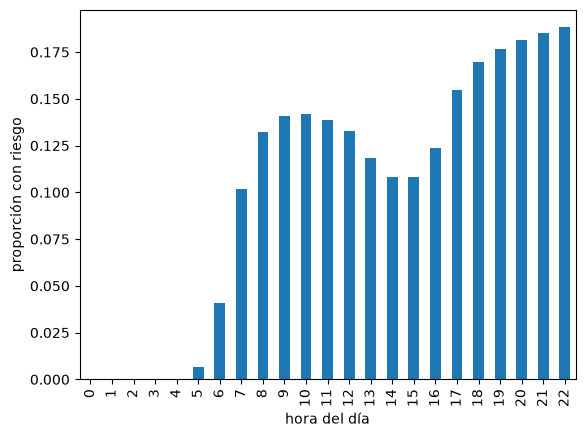

In [6]:
malla.groupby(malla["hora"].dt.hour)["riesgo"].mean().plot(kind="bar")
plt.xlabel("hora del día")
plt.ylabel("proporción con riesgo")
plt.show()

## Conclusiones

- La malla tiene 13.4 millones de filas (480 estaciones por hora, de junio de 2023 a septiembre de 2026). Las estaciones con capacidad 0 no entran porque no tienen inventario que estimar.
- El riesgo es la clase minoritaria: 10.5 % en entrenamiento, 8.3 % en validación y 8.6 % en prueba. Por eso el baseline de clase más frecuente nunca lo detecta y la exactitud no sirve como métrica.
- Las variables más relacionadas con el riesgo son las salidas y llegadas de la hora previa (correlación de 0.30 aprox.). El inventario y su proporción casi no tienen correlación lineal, pero era de esperarse porque el riesgo ocurre en los dos extremos (vacía o llena) y la correlación lineal no capta una relación en forma de U.
- El riesgo no se reparte parejo en el día: es casi cero de las 0 a las 4 h, sube desde las 5 h y llega a su máximo cerca de las 22 h (alrededor de 19 %). Como el inventario estimado se reinicia cada medianoche, se va alejando de la mitad de la capacidad conforme pasan las horas. Las 23 h no tienen etiqueta porque no se etiqueta el cambio de día.